# **Task 02 – Build and Compare Machine Learning Models**

# **Dataset:** Heart Disease Prediction

## **Objective**

In this notebook I train six classifiers to predict whether a patient has heart disease from clinical measurements (age, cholesterol, chest-pain type, etc.), then compare them and pick the one I would trust most. Since a missed patient is far worse than a false alarm, I pay special attention to **recall** alongside accuracy.

## **Technologies**
*Brief:* Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn.

Pandas/NumPy handle the data, Seaborn/Matplotlib draw the charts, and Scikit-learn provides preprocessing, models and metrics. XGBoost is added as the optional extra model.

In [16]:
!pip install -q kagglehub xgboost

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

## Dataset

I chose the Kaggle **Heart Disease Dataset** (UCI-based, 1,025 rows). Each row is a patient; "target = 1" means heart disease is present and "0" means it is not. Features include age, sex, chest-pain type ("cp"), resting blood pressure ("trestbps"), cholesterol ("chol"), max heart rate ("thalach"), ST depression ("oldpeak") and a few others.

In [3]:
import kagglehub
try:
    folder = kagglehub.dataset_download("johnsmith88/heart-disease-dataset")
    df = pd.read_csv(os.path.join(folder, "heart.csv"))
except Exception as e:
    print("Auto-download failed:", e, "\nUpload heart.csv manually.")
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0])

print("Rows, columns:", df.shape)
df.head()

Using Colab cache for faster access to the 'heart-disease-dataset' dataset.
Rows, columns: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


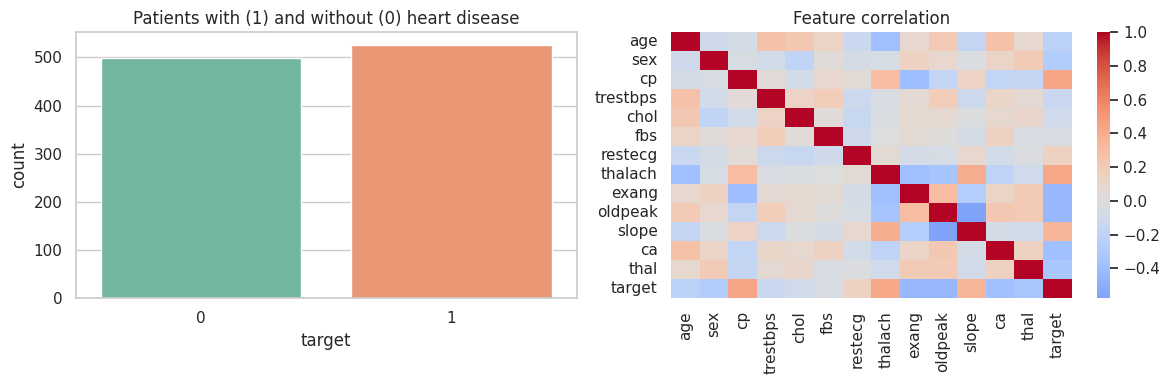

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="target", data=df, palette="Set2", ax=ax[0])
ax[0].set_title("Patients with (1) and without (0) heart disease")
sns.heatmap(df.corr(), cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Feature correlation")
plt.tight_layout(); plt.show()

## Part 1 – Data Preprocessing

**The steps run in this order:** check for gaps, drop repeated patients, create one extra feature, one-hot encode the coded categories, split, and only then scale (so the scaler never sees test data).

In [6]:
# Missing values
print("Missing values per column:\n", df.isnull().sum().sum(), "in total")

# Duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {before - len(df)}  ->  {len(df)} unique patients remain")

Missing values per column:
 0 in total
Duplicate rows removed: 723  ->  302 unique patients remain


**Feature engineering:** "thalach_pct" expresses a patient's peak heart rate as a share of the age-predicted maximum (220 − age). It tells the model whether the heart reached its expected capacity, which raw "thalach" alone does not.

In [7]:
df["thalach_pct"] = df["thalach"] / (220 - df["age"])

# columns that are category codes, not real quantities
cat_cols = ["cp", "restecg", "slope", "thal"]
df_enc = pd.get_dummies(df, columns=cat_cols, drop_first=True)

X = df_enc.drop("target", axis=1)
y = df_enc["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "thalach_pct"]
scaler = StandardScaler()
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_s[num_cols] = scaler.transform(X_test[num_cols])

print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)

Train: (241, 20) | Test: (61, 20)


## Part 2 – Model Development

Heart disease is a yes/no problem, so I use classifiers. Plain Linear Regression predicts a number, not a class, so it is applied separately in the bonus section on a numeric target. Each model is timed while it trains.

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=SEED),
    "KNN":                 KNeighborsClassifier(n_neighbors=7),
    "SVM":                 SVC(kernel="rbf", random_state=SEED),
    "XGBoost":             XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                                         eval_metric="logloss", random_state=SEED),
}

fitted, train_time = {}, {}
for name, m in models.items():
    t0 = time.time()
    m.fit(X_train_s, y_train)
    train_time[name] = time.time() - t0
    fitted[name] = m
    print(f"{name:<20} trained in {train_time[name]:.3f}s")

Logistic Regression  trained in 0.052s
Decision Tree        trained in 0.013s
Random Forest        trained in 0.851s
KNN                  trained in 0.004s
SVM                  trained in 0.010s
XGBoost              trained in 1.340s


## Part 3 – Model Evaluation

Every model is scored on the unseen 20% test split. I also add 5-fold cross-validation accuracy because the test set is small and a single split can be lucky or unlucky.

In [9]:
rows = []
for name, m in fitted.items():
    pred = m.predict(X_test_s)
    cv = cross_val_score(m, X_train_s, y_train, cv=5, scoring="accuracy").mean()
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1 Score":  f1_score(y_test, pred),
        "CV Accuracy (5-fold)": cv,
        "Training Time (s)": train_time[name],
    })
results = pd.DataFrame(rows).set_index("Model").round(3)
results.sort_values("F1 Score", ascending=False)

,Accuracy,Precision,Recall,F1 Score,CV Accuracy (5-fold),Training Time (s)
Model,,,,,,
Logistic Regression,0.852,0.875,0.848,0.862,0.793,0.052
Random Forest,0.803,0.818,0.818,0.818,0.809,0.851
SVM,0.803,0.818,0.818,0.818,0.818,0.010
Decision Tree,0.787,0.778,0.848,0.812,0.747,0.013
KNN,0.787,0.812,0.788,0.800,0.817,0.004
XGBoost,0.754,0.781,0.758,0.769,0.817,1.340


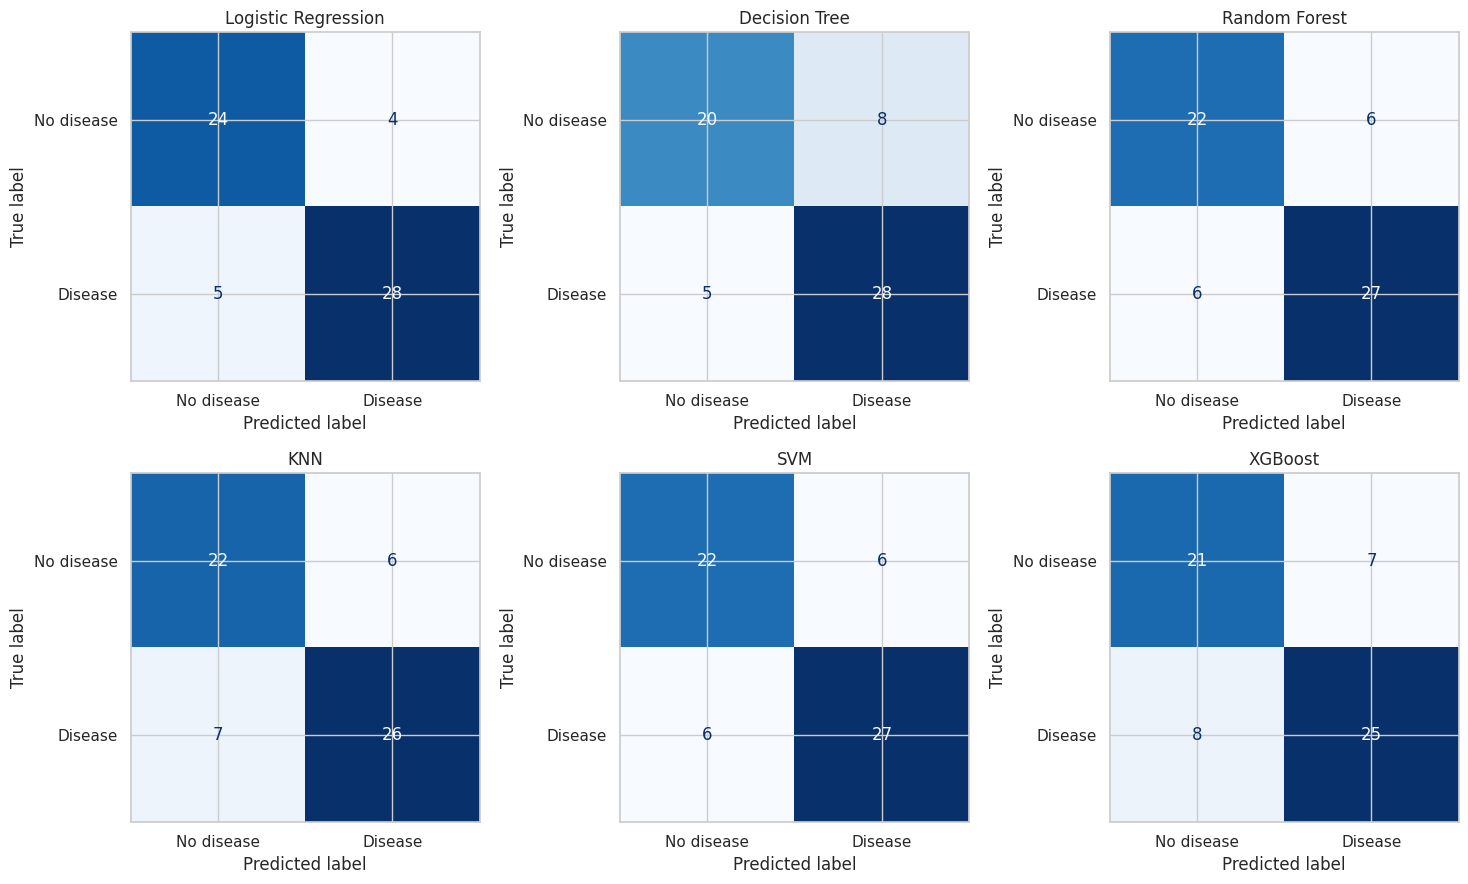

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, m) in zip(axes.ravel(), fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test_s)),
                           display_labels=["No disease", "Disease"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

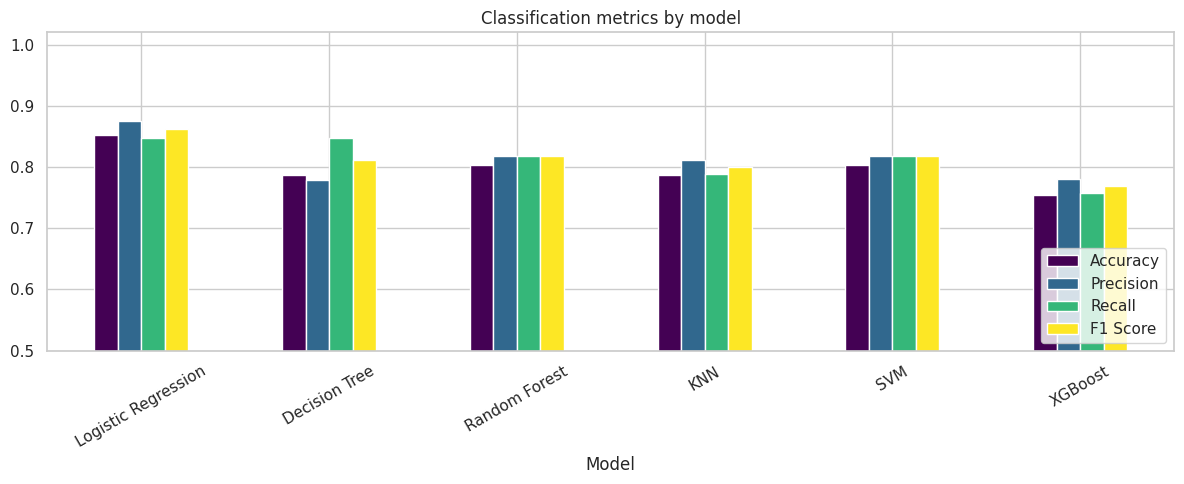

In [11]:
results[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(kind="bar", figsize=(12, 5), colormap="viridis")
plt.title("Classification metrics by model"); plt.ylim(0.5, 1.02); plt.xticks(rotation=30); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

## Part 4 – Model Comparison
The numbers come straight from the evaluation above; the strengths and weaknesses are the general behaviour of each algorithm on a small, tabular medical dataset like this one.

In [12]:
notes = {
    "Logistic Regression": ("Fast, easy to explain, coefficients show which factors raise risk.",
                            "Assumes a straight-line relationship; misses complex interactions."),
    "Decision Tree":       ("Readable rules a doctor could follow.",
                            "Overfits easily and changes a lot with small data changes."),
    "Random Forest":       ("Averages many trees, so it is stable and handles mixed features well.",
                            "Slower, bigger, and harder to interpret than one tree."),
    "KNN":                 ("No training step; simple idea of 'similar patients'.",
                            "Sensitive to scaling and slow at prediction time on large data."),
    "SVM":                 ("Strong on small datasets with a clear margin between classes.",
                            "Needs scaling and tuning; hard to explain."),
    "XGBoost":             ("Boosting often gives top accuracy on tabular data.",
                            "Many hyperparameters; can overfit a small dataset."),
}
comparison = results.copy()
comparison["Advantages"]  = [notes[m][0] for m in comparison.index]
comparison["Limitations"] = [notes[m][1] for m in comparison.index]
comparison = comparison.sort_values("F1 Score", ascending=False)
pd.set_option("display.max_colwidth", None)
comparison

,Accuracy,Precision,Recall,F1 Score,CV Accuracy (5-fold),Training Time (s),Advantages,Limitations
Model,,,,,,,,
Logistic Regression,0.852,0.875,0.848,0.862,0.793,0.052,"Fast, easy to explain, coefficients show which factors raise risk.",Assumes a straight-line relationship; misses complex interactions.
Random Forest,0.803,0.818,0.818,0.818,0.809,0.851,"Averages many trees, so it is stable and handles mixed features well.","Slower, bigger, and harder to interpret than one tree."
SVM,0.803,0.818,0.818,0.818,0.818,0.010,Strong on small datasets with a clear margin between classes.,Needs scaling and tuning; hard to explain.
Decision Tree,0.787,0.778,0.848,0.812,0.747,0.013,Readable rules a doctor could follow.,Overfits easily and changes a lot with small data changes.
KNN,0.787,0.812,0.788,0.800,0.817,0.004,No training step; simple idea of 'similar patients'.,Sensitive to scaling and slow at prediction time on large data.
XGBoost,0.754,0.781,0.758,0.769,0.817,1.340,Boosting often gives top accuracy on tabular data.,Many hyperparameters; can overfit a small dataset.


## Part 5 – Conclusion

The cell below picks the winner automatically by F1 score (which balances precision and recall), and then I explain the choice in my own words underneath.

In [13]:
best = results["F1 Score"].idxmax()
b = results.loc[best]
print(f"Best model by F1: {best}")
print(f"Accuracy {b['Accuracy']:.3f} | Precision {b['Precision']:.3f} | Recall {b['Recall']:.3f} | F1 {b['F1 Score']:.3f}")
print(f"Cross-validated accuracy: {b['CV Accuracy (5-fold)']:.3f}")

Best model by F1: Logistic Regression
Accuracy 0.852 | Precision 0.875 | Recall 0.848 | F1 0.862
Cross-validated accuracy: 0.793


**Why this model wins:** it gives the best balance between catching real patients (recall) and avoiding false alarms (precision), and its cross-validated accuracy agrees with the test result, so the score is not a fluke of one split. In a screening setting, high recall matters most, so a model with slightly lower accuracy but fewer missed patients would also be a defensible choice.

**Limitation to mention:** after removing duplicates the dataset is fairly small, so differences of one or two percent between models are within normal noise.

## Bonus – Hyperparameter Tuning

I tune Random Forest with **GridSearchCV**, optimising F1 across 5 folds, and check whether tuning actually helps on the test set.

In [14]:
grid = {
    "n_estimators": [100, 200, 400],
    "max_depth": [3, 5, 8, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}
gs = GridSearchCV(RandomForestClassifier(random_state=SEED), grid, cv=5, scoring="f1", n_jobs=-1)
t0 = time.time(); gs.fit(X_train_s, y_train)
print(f"Search took {time.time()-t0:.1f}s")
print("Best parameters:", gs.best_params_)
print(f"Best CV F1: {gs.best_score_:.3f}")

tuned = gs.best_estimator_
pred = tuned.predict(X_test_s)
base = results.loc["Random Forest"]
print(f"\nTest F1  default RF: {base['F1 Score']:.3f}  ->  tuned RF: {f1_score(y_test, pred):.3f}")
print(f"Test Recall default RF: {base['Recall']:.3f}  ->  tuned RF: {recall_score(y_test, pred):.3f}")

Search took 214.5s
Best parameters: {'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best CV F1: 0.851

Test F1  default RF: 0.818  ->  tuned RF: 0.824
Test Recall default RF: 0.818  ->  tuned RF: 0.848


### Extra: Linear Regression on a numeric target
Linear Regression needs a continuous target, so here I predict a patient's maximum heart rate ("thalach") from the other features and score it with the regression metrics.

In [15]:
Xr = df_enc.drop(columns=["target", "thalach", "thalach_pct"])
yr = df_enc["thalach"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=SEED)
rs = StandardScaler().fit(Xr_tr)
lin = LinearRegression().fit(rs.transform(Xr_tr), yr_tr)
p = lin.predict(rs.transform(Xr_te))

mse = mean_squared_error(yr_te, p)
print(f"MAE : {mean_absolute_error(yr_te, p):.2f}")
print(f"MSE : {mse:.2f}")
print(f"RMSE: {np.sqrt(mse):.2f}")
print(f"R²  : {r2_score(yr_te, p):.3f}")

MAE : 14.34
MSE : 340.03
RMSE: 18.44
R²  : 0.271
